In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "train_FD001.txt"
RESULTS_PATH = PROJECT_ROOT / "results" / "figures"

RESULTS_PATH.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT)
print("Data file:", DATA_PATH)
print("File exists:", DATA_PATH.exists())

Project folder: /Users/aisha/mma3001-project
Data file: /Users/aisha/mma3001-project/data/raw/train_FD001.txt
File exists: True


In [3]:
index_columns = [
    "engine_id",
    "cycle",
]

setting_columns = [
    "setting_1",
    "setting_2",
    "setting_3",
]

sensor_columns = [
    f"sensor_{number}" for number in range(1, 22)
]

column_names = index_columns + setting_columns + sensor_columns

print(column_names)
print("Number of columns:", len(column_names))

['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']
Number of columns: 26


In [4]:
train = pd.read_csv(
    DATA_PATH,
    sep=r"\s+",
    header=None,
    names=column_names
)

print(train.head())
print("\nDataset shape:", train.shape)

   engine_id  cycle  setting_1  setting_2  setting_3  sensor_1  sensor_2  \
0          1      1    -0.0007    -0.0004      100.0    518.67    641.82   
1          1      2     0.0019    -0.0003      100.0    518.67    642.15   
2          1      3    -0.0043     0.0003      100.0    518.67    642.35   
3          1      4     0.0007     0.0000      100.0    518.67    642.35   
4          1      5    -0.0019    -0.0002      100.0    518.67    642.37   

   sensor_3  sensor_4  sensor_5  ...  sensor_12  sensor_13  sensor_14  \
0   1589.70   1400.60     14.62  ...     521.66    2388.02    8138.62   
1   1591.82   1403.14     14.62  ...     522.28    2388.07    8131.49   
2   1587.99   1404.20     14.62  ...     522.42    2388.03    8133.23   
3   1582.79   1401.87     14.62  ...     522.86    2388.08    8133.83   
4   1582.85   1406.22     14.62  ...     522.19    2388.04    8133.80   

   sensor_15  sensor_16  sensor_17  sensor_18  sensor_19  sensor_20  sensor_21  
0     8.4195       0.03

In [5]:
print("Number of engines:", train["engine_id"].nunique())
print("Number of rows:", len(train))
print("Missing values:", train.isna().sum().sum())
print("Duplicated rows:", train.duplicated().sum())

print("\nData types:")
print(train.dtypes)

print("\nSummary:")
print(train.describe().T)

Number of engines: 100
Number of rows: 20631
Missing values: 0
Duplicated rows: 0

Data types:
engine_id      int64
cycle          int64
setting_1    float64
setting_2    float64
setting_3    float64
sensor_1     float64
sensor_2     float64
sensor_3     float64
sensor_4     float64
sensor_5     float64
sensor_6     float64
sensor_7     float64
sensor_8     float64
sensor_9     float64
sensor_10    float64
sensor_11    float64
sensor_12    float64
sensor_13    float64
sensor_14    float64
sensor_15    float64
sensor_16    float64
sensor_17      int64
sensor_18      int64
sensor_19    float64
sensor_20    float64
sensor_21    float64
dtype: object

Summary:
             count         mean           std        min        25%  \
engine_id  20631.0    51.506568  2.922763e+01     1.0000    26.0000   
cycle      20631.0   108.807862  6.888099e+01     1.0000    52.0000   
setting_1  20631.0    -0.000009  2.187313e-03    -0.0087    -0.0015   
setting_2  20631.0     0.000002  2.930621e-04    -0

In [6]:
maximum_cycles = (
    train.groupby("engine_id")["cycle"]
    .max()
    .rename("maximum_cycle")
)

train = train.merge(
    maximum_cycles,
    on="engine_id",
    how="left",
    validate="many_to_one"
)

train["RUL"] = train["maximum_cycle"] - train["cycle"]

print(
    train[
        ["engine_id", "cycle", "maximum_cycle", "RUL"]
    ].head(10)
)

   engine_id  cycle  maximum_cycle  RUL
0          1      1            192  191
1          1      2            192  190
2          1      3            192  189
3          1      4            192  188
4          1      5            192  187
5          1      6            192  186
6          1      7            192  185
7          1      8            192  184
8          1      9            192  183
9          1     10            192  182


In [7]:
print(
    train.loc[
        train["engine_id"] == 1,
        ["engine_id", "cycle", "maximum_cycle", "RUL"]
    ].tail()
)

     engine_id  cycle  maximum_cycle  RUL
187          1    188            192    4
188          1    189            192    3
189          1    190            192    2
190          1    191            192    1
191          1    192            192    0


In [8]:
assert train["RUL"].min() == 0
assert (train["RUL"] >= 0).all()
assert train["engine_id"].nunique() == 100
assert train.isna().sum().sum() == 0

final_rul = train.groupby("engine_id")["RUL"].last()
assert (final_rul == 0).all()

print("All RUL checks passed.")

All RUL checks passed.


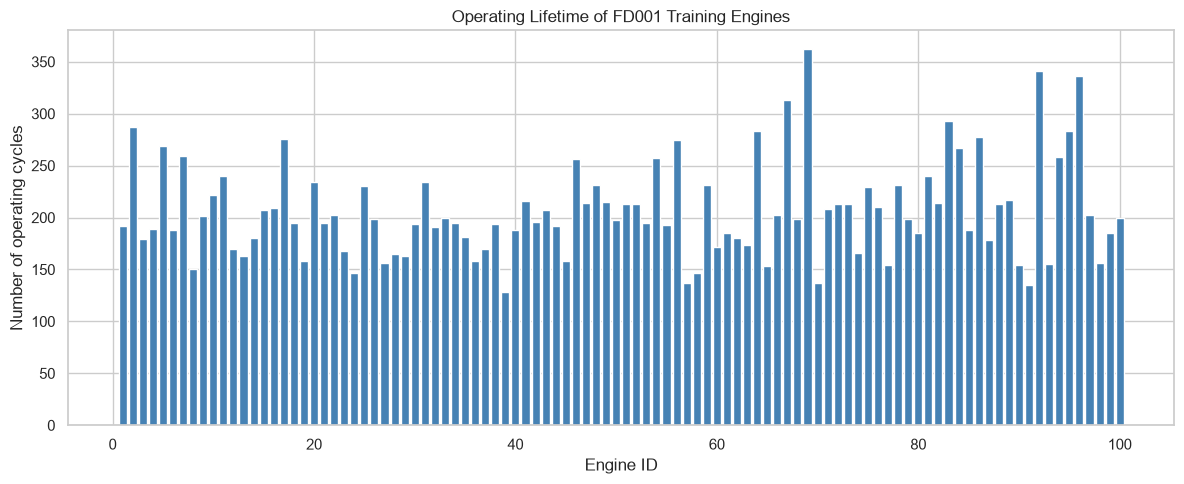

In [9]:
engine_lifetimes = train.groupby("engine_id")["cycle"].max()

plt.figure(figsize=(12, 5))
plt.bar(
    engine_lifetimes.index,
    engine_lifetimes.values,
    color="steelblue"
)

plt.xlabel("Engine ID")
plt.ylabel("Number of operating cycles")
plt.title("Operating Lifetime of FD001 Training Engines")
plt.tight_layout()

plt.savefig(
    RESULTS_PATH / "engine_lifetimes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

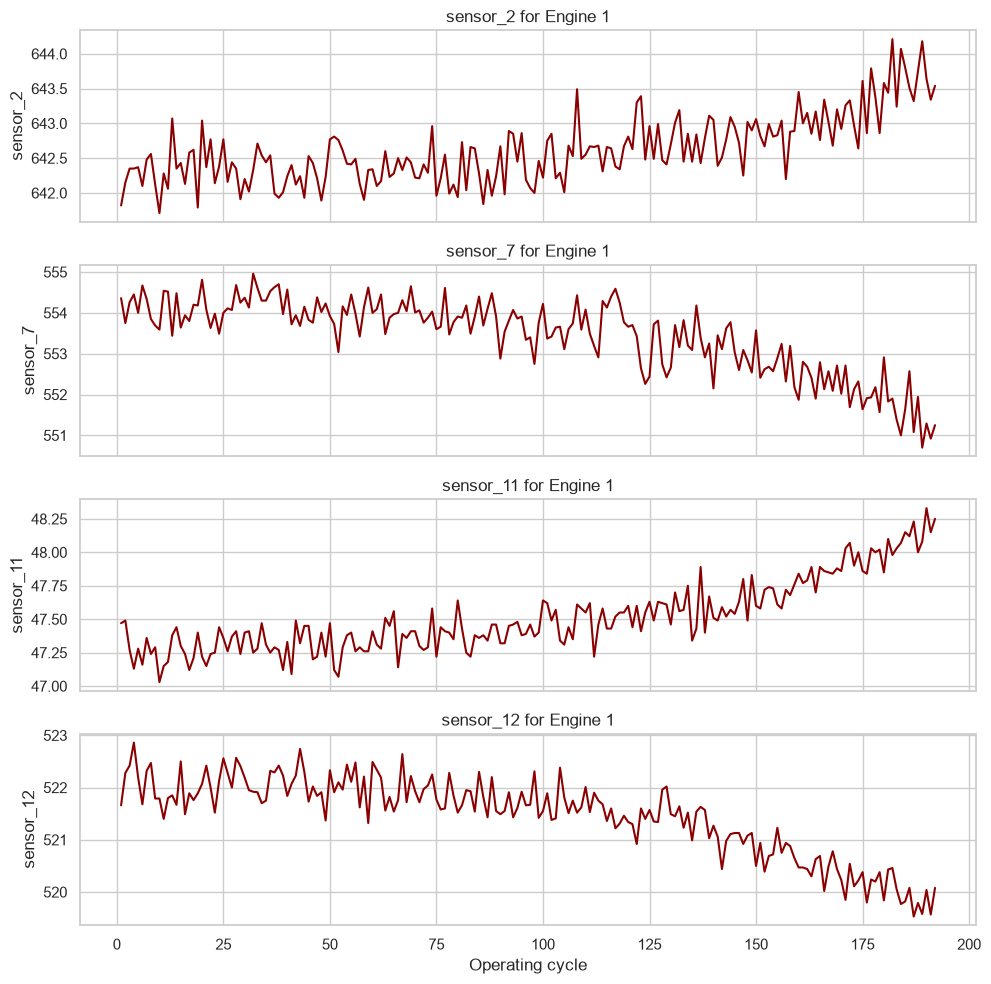

In [10]:
engine_number = 1

engine_data = train[
    train["engine_id"] == engine_number
].copy()

selected_sensors = [
    "sensor_2",
    "sensor_7",
    "sensor_11",
    "sensor_12",
]

fig, axes = plt.subplots(
    len(selected_sensors),
    1,
    figsize=(10, 10),
    sharex=True
)

for axis, sensor in zip(axes, selected_sensors):
    axis.plot(
        engine_data["cycle"],
        engine_data[sensor],
        color="darkred"
    )

    axis.set_ylabel(sensor)
    axis.set_title(f"{sensor} for Engine {engine_number}")

axes[-1].set_xlabel("Operating cycle")

plt.tight_layout()

plt.savefig(
    RESULTS_PATH / "engine_1_sensor_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
sensor_statistics = train[sensor_columns].agg(
    ["mean", "std", "min", "max"]
).T

constant_sensors = sensor_statistics[
    sensor_statistics["std"] < 1e-8
].index.tolist()

print("Constant sensors:", constant_sensors)
print(sensor_statistics)

Constant sensors: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
                  mean           std        min        max
sensor_1    518.670000  0.000000e+00   518.6700   518.6700
sensor_2    642.680934  5.000533e-01   641.2100   644.5300
sensor_3   1590.523119  6.131150e+00  1571.0400  1616.9100
sensor_4   1408.933782  9.000605e+00  1382.2500  1441.4900
sensor_5     14.620000  5.329200e-15    14.6200    14.6200
sensor_6     21.609803  1.388985e-03    21.6000    21.6100
sensor_7    553.367711  8.850923e-01   549.8500   556.0600
sensor_8   2388.096652  7.098548e-02  2387.9000  2388.5600
sensor_9   9065.242941  2.208288e+01  9021.7300  9244.5900
sensor_10     1.300000  0.000000e+00     1.3000     1.3000
sensor_11    47.541168  2.670874e-01    46.8500    48.5300
sensor_12   521.413470  7.375534e-01   518.6900   523.3800
sensor_13  2388.096152  7.191892e-02  2387.8800  2388.5600
sensor_14  8143.752722  1.907618e+01  8099.9400  8293.7200
sensor_15     8.4421

In [12]:
usable_sensors = [
    sensor
    for sensor in sensor_columns
    if sensor not in constant_sensors
]

print("Usable sensors:", usable_sensors)
print("Number of usable sensors:", len(usable_sensors))

Usable sensors: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Number of usable sensors: 15


In [13]:
feature_columns = (
    ["cycle"]
    + setting_columns
    + usable_sensors
)

X = train[feature_columns].copy()
y = train["RUL"].copy()
groups = train["engine_id"].copy()

print("Feature matrix:", X.shape)
print("Target:", y.shape)

Feature matrix: (20631, 19)
Target: (20631,)


In [14]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

train_indices, validation_indices = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_indices]
X_validation = X.iloc[validation_indices]

y_train = y.iloc[train_indices]
y_validation = y.iloc[validation_indices]

training_engines = set(groups.iloc[train_indices])
validation_engines = set(groups.iloc[validation_indices])

print("Training engines:", len(training_engines))
print("Validation engines:", len(validation_engines))
print("Shared engines:", training_engines & validation_engines)

assert training_engines.isdisjoint(validation_engines)

Training engines: 80
Validation engines: 20
Shared engines: set()


In [15]:
def evaluate_model(name, y_true, y_prediction):
    """Calculate regression performance metrics."""

    mae = mean_absolute_error(y_true, y_prediction)
    rmse = np.sqrt(
        mean_squared_error(y_true, y_prediction)
    )
    r_squared = r2_score(y_true, y_prediction)

    return {
        "model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r_squared,
    }

In [16]:
mean_training_rul = y_train.mean()

baseline_predictions = np.full(
    shape=len(y_validation),
    fill_value=mean_training_rul
)

results = [
    evaluate_model(
        "Mean RUL baseline",
        y_validation,
        baseline_predictions
    )
]

pd.DataFrame(results)

,model,MAE,RMSE,R2
0,Mean RUL baseline,55.363284,65.715445,-0.001937


In [17]:
linear_model = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "regressor",
            LinearRegression()
        ),
    ]
)

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_validation)

results.append(
    evaluate_model(
        "Linear regression",
        y_validation,
        linear_predictions
    )
)

pd.DataFrame(results).round(3)

,model,MAE,RMSE,R2
0,Mean RUL baseline,55.363,65.715,-0.002
1,Linear regression,25.155,31.656,0.768


In [18]:
random_forest = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=15,
                min_samples_leaf=2,
                n_jobs=-1,
                random_state=RANDOM_STATE
            )
        ),
    ]
)

random_forest.fit(X_train, y_train)

forest_predictions = random_forest.predict(X_validation)

results.append(
    evaluate_model(
        "Random Forest",
        y_validation,
        forest_predictions
    )
)

results_table = (
    pd.DataFrame(results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print(results_table.round(3))

               model     MAE    RMSE     R2
0      Random Forest  23.782  31.312  0.773
1  Linear regression  25.155  31.656  0.768
2  Mean RUL baseline  55.363  65.715 -0.002


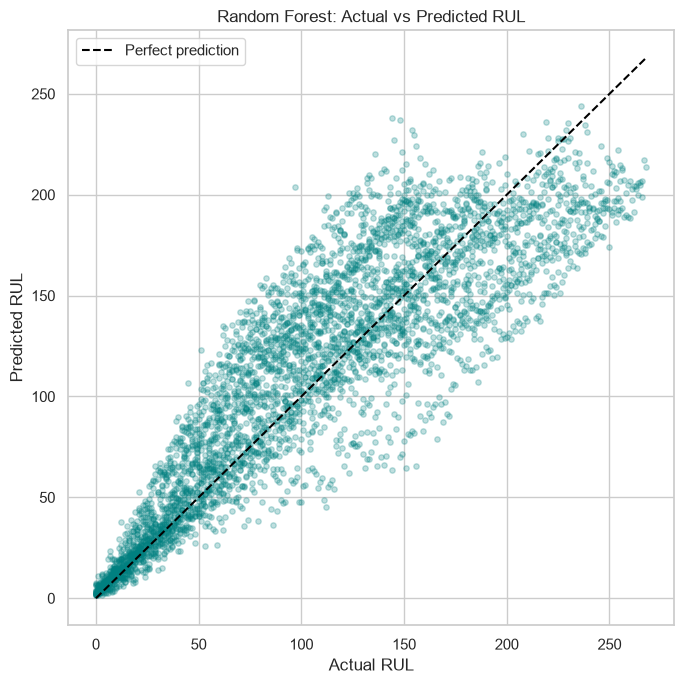

In [19]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_validation,
    forest_predictions,
    alpha=0.25,
    s=15,
    color="teal"
)

minimum_value = min(
    y_validation.min(),
    forest_predictions.min()
)

maximum_value = max(
    y_validation.max(),
    forest_predictions.max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
    color="black",
    label="Perfect prediction"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Random Forest: Actual vs Predicted RUL")
plt.legend()
plt.tight_layout()

plt.savefig(
    RESULTS_PATH / "random_forest_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
metrics_path = PROJECT_ROOT / "results" / "metrics"
metrics_path.mkdir(parents=True, exist_ok=True)

results_table.to_csv(
    metrics_path / "initial_model_results.csv",
    index=False
)

print("Results saved to:", metrics_path)

Results saved to: /Users/aisha/mma3001-project/results/metrics


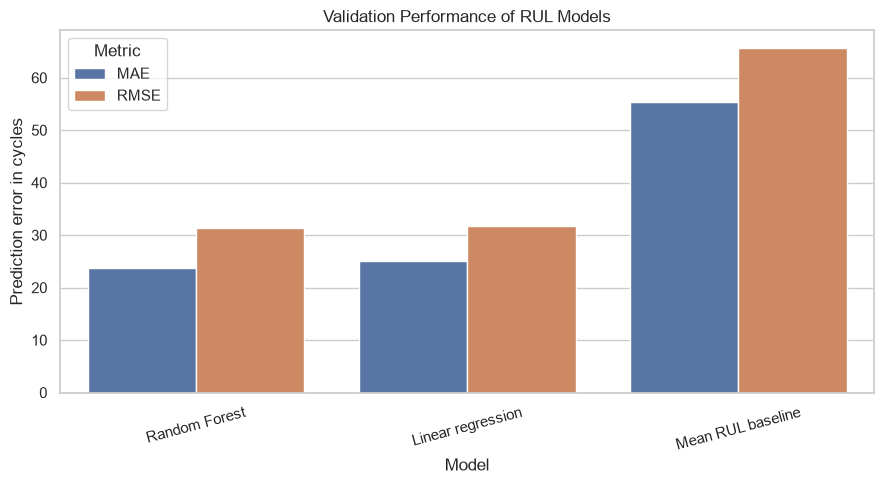

In [22]:
results_plot = results_table.melt(
    id_vars="model",
    value_vars=["MAE", "RMSE"],
    var_name="Metric",
    value_name="Error"
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_plot,
    x="model",
    y="Error",
    hue="Metric"
)

plt.xlabel("Model")
plt.ylabel("Prediction error in cycles")
plt.title("Validation Performance of RUL Models")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    RESULTS_PATH / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()